# Задание 4 (продолжение): Эксперимент Б, Эксперимент В и контрольные задания

Калибровка шкалы и Эксперимент А сделаны в `task3_4.py`. Этот файл самостоятельный: сначала он повторяет оттуда только то, без чего дальше не обойтись, потом решает оставшиеся пункты.

**Мини-словарь.**
- **Активация $x$** — 512 чисел, в которых Pythia на слое 3 хранит всё, что «знает» про очередной токен (слово или кусок слова). Внутренняя «мысль» модели в виде вектора.
- **Нейрон $i$** — просто $i$-е из этих 512 чисел. Толкнуть нейрон — прибавить к вектору $\alpha \cdot e_i$, где $e_i = (0, \dots, 0, 1, 0, \dots, 0)$, единица на месте $i$.
- **Латент (фича) SAE** — одно из 2048 направлений, на которые автоэнкодер из задания 3 раскладывает активацию. Хороший латент отвечает за одно понятие, например «открылась скобка».
- **Стиринг** (steering, «рулёжка») — прямо во время работы модели прибавляем к активации вектор $\alpha \cdot v$ и смотрим, как меняется текст. $v$ — направление (длина 1), $\alpha$ — сила толчка.
- **Моносемантичный** — отвечает за одно понятие. **Полисемантичный** — за смесь несвязанных.

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
import matplotlib.pyplot as plt
import marimo as mo
import pandas as pd
import torch.nn as nn
import torch

## Подготовка (повтор из `task3_4.py`)

**Что делаем.** Загружаем Pythia-70m и заново собираем активации слоя 3 тем же кодом, что в `task3_4.py`: 512 текстов из pile-10k по 128 токенов, первый токен каждого выбрасываем, получается 65 024 вектора по 512 чисел. Класс исправленного SAE и функцию обучения копируем из задания 3 без изменений и обучаем SAE заново. Всё вместе — меньше минуты.

**Зачем.** Переменные из другого файла сюда не попадают, а SAE нужен для экспериментов Б и В. `torch.manual_seed(69)` фиксирует случайность: при каждом запуске получается тот же SAE и тот же номер латента, поэтому выводы в тексте ниже совпадают с тем, что напечатает ноутбук.

In [ ]:
torch.set_num_threads(4)

name = 'EleutherAI/pythia-70m'
model = AutoModelForCausalLM.from_pretrained(name).eval()
tokenizer = AutoTokenizer.from_pretrained(name)

texts = load_dataset('NeelNanda/pile-10k', split='train')['text'][:10000]
tokens = tokenizer(texts, truncation=True, max_length=128)['input_ids']
sequences = [t for t in tokens if len(t) == 128][:512]
ids = torch.tensor(sequences)

saved = []
def hook(module, inputs, outputs):
    if isinstance(outputs, (tuple, list)):
        outputs = outputs[0]

    saved.append(outputs.detach().cpu())

layer = 3
layer_module = model.gpt_neox.layers[layer]

handle = layer_module.register_forward_hook(hook)
try:
    with torch.inference_mode():
        for batch in ids.split(16):
            model.gpt_neox(batch, use_cache=False)
finally:
    handle.remove()

X = torch.cat(saved)[:, 1:].reshape(-1, 512).float()
print(f'Активации: {X.shape}')

tokenizer.pad_token = tokenizer.eos_token

Loading weights: 100%|██████████| 76/76 [00:00<00:00, 4951.72it/s]
Using the latest cached version of the dataset since NeelNanda/pile-10k couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'default' at C:\Users\compl\.cache\huggingface\datasets\NeelNanda___pile-10k\default\0.0.0\127bfedcd5047750df5ccf3a12979a47bfa0bafa (last modified on Fri Oct  9 15:35:31 2026).


Активации: torch.Size([65024, 512])


In [ ]:
class FixedTopKSAE(nn.Module):
    def __init__(self, x_mean, d_model=512, d_sae=2048, k=32):
        super().__init__()
        self.k = k

        W = torch.randn(d_sae, d_model)
        W = W / W.norm(dim=1, keepdim=True)

        self.W_enc = nn.Parameter(W.T.clone())
        self.b_enc = nn.Parameter(torch.zeros(d_sae))

        self.W_dec = nn.Parameter(W.clone())
        self.b_dec = nn.Parameter(x_mean.clone())

    def encode(self, x):
        pre_acts = (x - self.b_dec) @ self.W_enc + self.b_enc
        val, idx = torch.topk(pre_acts, self.k, dim=-1)
        acts = torch.zeros_like(pre_acts).scatter_(-1, idx, torch.relu(val))
        return acts

    def decode(self, acts):
        return acts @ (self.W_dec / self.W_dec.norm(dim=1, keepdim=True)) + self.b_dec

    def forward(self, x):
        acts = self.encode(x)
        x_hat = self.decode(acts)
        return x_hat, acts

In [ ]:
def train_sae(net, X):
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    ev_history = []
    seen = torch.zeros(2048, dtype=torch.bool)

    for step in range(1000):
        x = X[torch.randint(len(X), (64,))]
        x_hat, acts = net(x)
        loss = (x - x_hat).square().mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if step >= 500:
            with torch.no_grad():
                ev = 1 - (x - x_hat).var(dim=-1, unbiased=False).mean() / x.var(dim=-1, unbiased=False).mean().clamp_min(1e-12)
                ev_history.append(ev.item())
                seen |= (acts != 0).any(dim=0)

    return sum(ev_history) / 500, (~seen).float().mean().item()


torch.manual_seed(69)
sae = FixedTopKSAE(X.mean(dim=0))
ev_sae, dead_sae = train_sae(sae, X)
print(f'SAE: Explained Variance = {ev_sae:.1%}, Dead Latents = {dead_sae:.1%}')

SAE: Explained Variance = 84.0%, Dead Latents = 0.0%


**Что делаем.** Собираем в одном месте хуки:
- `layer_output(batch)` — прогоняет тексты через модель и возвращает то, что выдал слой 3 (как `capture` в `task3_4.py`);
- `make_steering_hook` и `generate` — без изменений из Эксперимента А: хук прибавляет $\alpha \cdot v$ к выходу слоя 3, `generate` жадно дописывает к промпту 25 токенов;
- `e` — тот же базисный вектор $e_{42}$.

**Зачем.** Хук (hook, «крючок») — функция, которую PyTorch сам вызывает каждый раз, когда слой посчитал результат. Так можно подсмотреть или подменить выход слоя прямо во время генерации, не меняя саму модель.

In [ ]:
def layer_output(batch):
    saved = []
    def capture(module, inputs, output):
        saved.append(output[0] if isinstance(output, (tuple, list)) else output)

    handle = layer_module.register_forward_hook(capture)
    try:
        with torch.inference_mode():
            model(**batch, use_cache=False)
    finally:
        handle.remove()
    return saved[0]


def make_steering_hook(direction, alpha):
    def change(module, inputs, output):
        x = output[0] if isinstance(output, (tuple, list)) else output
        direction_for_x = direction.to(device=x.device, dtype=x.dtype)
        changed = x + alpha * direction_for_x

        if isinstance(output, tuple):
            return (changed,) + output[1:]
        if isinstance(output, list):
            return [changed] + output[1:]
        return changed

    return change


prompt = tokenizer(
    "In the middle of the room there was a large table with",
    return_tensors='pt'
)

def generate(direction, alpha):
    handle = layer_module.register_forward_hook(make_steering_hook(direction, alpha))
    try:
        with torch.inference_mode():
            result = model.generate(
                **prompt,
                max_new_tokens=25,
                do_sample=False,
                pad_token_id=tokenizer.eos_token_id
            )
    finally:
        handle.remove()

    start = prompt['input_ids'].shape[1]
    return tokenizer.decode(result[0, start:], skip_special_tokens=True)

e = torch.zeros(512)
e[42] = 1.0

**Что делаем.** Повторяем калибровку: средняя длина вектора активации $\mathbb{E}\|x\|_2$ на 16 нейтральных предложениях и сетка $\alpha$ из её долей — те же числа, что в `task3_4.py`. Новое только одно: печатаем ещё и медиану.

**Зачем медиана.** Среднее (43.4) завышено двумя «выбросами» в каждом предложении: у первого токена и у финальной точки длина вектора больше 100. У обычного слова она около 14. Это пригодится в контрольном задании 3: уже при $\alpha = 0.3 \cdot 43.4 \approx 13$ добавка длиной с целый обычный токен.

In [ ]:
neutral_texts = [
    "The cat slept near the window.",
    "The train arrived at the station in the morning.",
    "She opened a book and started reading.",
    "It was a warm day in the quiet village.",
    "They went to the market to buy vegetables.",
    "He put the keys on the kitchen table.",
    "The children played outside after school.",
    "A small boat sailed slowly across the lake.",
    "The teacher explained the lesson to the class.",
    "We walked through the park before dinner.",
    "The old house stood at the end of the road.",
    "They finished their work and went home.",
    "The weather changed during the afternoon.",
    "She received a letter from her friend.",
    "The shop was closed on Sunday.",
    "A gentle breeze moved the leaves on the trees.",
]
neutral = tokenizer(
    neutral_texts,
    padding=True,
    return_tensors='pt'
)

norms = layer_output(neutral)[neutral['attention_mask'].bool()].norm(dim=-1)
mean_norm = norms.mean().item()
levels = [0.1, 0.3, 0.5, 0.8, 1.0, 1.2, 1.5]
report_levels = [0.1, 0.8, 1.5]
print(f'Средняя L2-норма: {mean_norm:.4f}, медиана: {norms.median():.4f}')
print(f'alpha: {[round(k * mean_norm, 3) for k in levels]}')

Средняя L2-норма: 43.3750, медиана: 14.1484
alpha: [4.338, 13.012, 21.688, 34.7, 43.375, 52.05, 65.062]


## Эксперимент Б. Ищем моносемантический латент SAE

![alt](public/task4_4.png)

**Что делаем.**
1. Проверочный набор — 30 предложений: 14 с открывающими скобками `(`, `[`, `{` (6 обычных фраз с пояснением в скобках и 8 строк кода или формул) и 16 нейтральных из калибровки.
2. Прогоняем их через Pythia до слоя 3, затем через энкодер SAE. Формула из условия $f(x) = \mathrm{ReLU}(W_{enc}(x - b_{dec}) + b_{enc})$ — это `sae.encode`; наш Top-K SAE вдобавок оставляет только 32 самых сильных латента, остальные обнуляет. Первый токен каждого предложения выбрасываем, как при обучении SAE в задании 3: его вектор аномально длинный, таких SAE не видел.
3. Целевые токены — те, где есть открывающая скобка. Для каждого из 2048 латентов считаем два числа: среднюю активацию на скобках (условие 1, должна быть $\gg 0$) и долю нулей на всех остальных токенах (условие 2, нужно $\ge 99\%$).
4. Среди латентов, прошедших условие 2, берём тот, у кого средняя активация на скобках самая большая.

**Зачем.** Ищем «выключатель» одного узкого понятия. Условие 2 отсекает ловушку из условия — «латент пунктуации вообще»: он загорался бы и на точках, запятых, закрывающих скобках и не набрал бы 99 % нулей.

**Как рассказать.** «Латент моносемантичен, если включается на своём понятии и молчит почти везде ещё. Я проверил оба условия на 30 предложениях и выбрал латент автоматически по этим условиям, а не по максимуму на одном примере».

In [ ]:
bracket_texts = [
    "The result (see Table 2) was better than expected.",
    "The meeting (which lasted three hours) ended at noon.",
    "She bought apples (red and green) at the market.",
    "Most students (about 80 percent) passed the exam.",
    "The museum (opened in 1920) is free on Mondays.",
    "Our team (five people in total) finished the project early.",
    "The function print(x) writes the value to the screen.",
    "if (a > b) { return a; } else { return b; }",
    "for (int i = 0; i < n; i++) { sum += arr[i]; }",
    "Let f(x) = (x + 1) * (x - 1) for all real x.",
    "data = {'name': 'Alice', 'age': 30}",
    "values = [1, 2, 3, 4, 5]",
    "matrix[i][j] = matrix[j][i] + 1",
    "def add(a, b): return (a + b)",
]
check = tokenizer(
    bracket_texts + neutral_texts,
    padding=True,
    return_tensors='pt'
)

real = check['attention_mask'].bool()
real[:, 0] = False
with torch.inference_mode():
    f = sae.encode(layer_output(check)[real].float())

check_tokens = [tokenizer.decode([t]) for t in check['input_ids'][real].tolist()]
target = torch.tensor([any(c in t for c in '([{') for t in check_tokens])

mean_target = f[target].mean(dim=0)
zero_other = (f[~target] == 0).float().mean(dim=0)
j = torch.where(zero_other >= 0.99, mean_target, -1.0).argmax().item()

print(f'Токенов: {len(check_tokens)}, целевых (открывающие скобки): {target.sum().item()}, остальных: {(~target).sum().item()}')
print(f'Латентов, которые молчат на >= 99% остальных токенов: {(zero_other >= 0.99).sum().item()} из 2048')
print(f'Выбран латент j = {j}: E[f_j] на скобках = {mean_target[j]:.2f}, на остальных = {f[~target, j].mean():.2f}, нулей на остальных = {zero_other[j]:.1%}')

Токенов: 308, целевых (открывающие скобки): 24, остальных: 284
Латентов, которые молчат на >= 99% остальных токенов: 1260 из 2048
Выбран латент j = 370: E[f_j] на скобках = 0.58, на остальных = 0.00, нулей на остальных = 100.0%


**Что делаем.** Показываем 5 мест проверочного набора, где выбранный латент активен сильнее всего: $f_j$ — сила активации, токен подсвечен в контексте.

**Зачем.** Условие требует глазами убедиться, что латент про одно понятие, прежде чем им рулить.

In [ ]:
_where = real.nonzero()
_rows = []
for _value, _i in zip(*f[:, j].topk(5)):
    _s, _p = _where[_i].tolist()
    _ids = check['input_ids'][_s]
    _token = tokenizer.decode(_ids[_p:_p + 1])
    _rows.append({
        '$f_j$': f'{_value:.2f}',
        'токен': f'`{_token}`',
        'контекст': tokenizer.decode(_ids[:_p]) + f'<mark>{_token}</mark>' + tokenizer.decode(_ids[_p + 1:], skip_special_tokens=True),
    })
mo.md(pd.DataFrame(_rows).to_markdown(index=False))

|   $f_j$ | токен   | контекст                                                                 |
|--------:|:--------|:-------------------------------------------------------------------------|
|    2.47 | ` (`    | Our team<mark> (</mark>five people in total) finished the project early. |
|    2.27 | ` (`    | The museum<mark> (</mark>opened in 1920) is free on Mondays.             |
|    2.27 | ` (`    | She bought apples<mark> (</mark>red and green) at the market.            |
|    2.2  | ` (`    | The result<mark> (</mark>see Table 2) was better than expected.          |
|    2.04 | ` (`    | The meeting<mark> (</mark>which lasted three hours) ended at noon.       |

**Что видно.** Все пять — открывающая круглая скобка ` (` в обычной фразе перед пояснением: «(five people in total)», «(opened in 1920)», «(see Table 2)». На 284 нецелевых токенах латент не включился ни разу (100 % нулей). Средняя активация на всех 24 скобках — 0.58, хотя на скобках-пояснениях она ≈ 2.2: значит, на скобках в коде (`print(x)`, `arr[i]`, `{`) латент почти не включается. Это даже более узкое понятие, чем «все скобки»: **«в обычном тексте открылась скобка-пояснение»**. Сила активации в реальном тексте — не больше ≈ 2.5; это число понадобится дальше.

## Эксперимент В. Feature Steering

> Возьмите столбец декодера $d_j = W_{dec}[:, j]$, нормализуйте: $v_{SAE} = d_j / \|d_j\|_2$. Примените $x \leftarrow x + \alpha \cdot v_{SAE}$ на том же слое, с тем же промптом и теми же $\alpha$, что в Эксперименте А.

**Что делаем.** В условии $W_{dec}$ размера $512 \times 2048$, а в нашем классе он хранится транспонированным ($2048 \times 512$), поэтому «столбец $j$» — это строка `sae.W_dec[j]`. Это то направление, которое декодер добавляет к вектору, когда латент $j$ включается. Делим на длину и получаем $v_{SAE}$ длины 1 — как у $e_{42}$. Значит, при одном и том же $\alpha$ оба толчка одинаковой силы, и сравнение честное.

Сразу собираем таблицу для контрольного задания 1: базовая модель, нейрон и фича при трёх $\alpha$ из Эксперимента А — слабом (0.1 нормы), среднем (0.8) и сильном (1.5). Символ ⏎ — перенос строки.

In [ ]:
v_sae = (sae.W_dec[j] / sae.W_dec[j].norm()).detach()

def _row(vector, direction, k):
    text = generate(direction, k * mean_norm).replace('\n', '⏎')
    return {'вектор': vector, 'α / E‖x‖': k, 'α': round(k * mean_norm, 1), 'продолжение промпта': text}

_rows = [_row('нет (базовая модель)', e, 0.0)]
_rows += [_row('нейрон e_42', e, k) for k in report_levels]
_rows += [_row(f'фича SAE j = {j}', v_sae, k) for k in report_levels]
mo.md(pd.DataFrame(_rows).to_markdown(index=False))

| вектор               |   α / E‖x‖ |    α | продолжение промпта                                                                                                           |
|:---------------------|-----------:|-----:|:------------------------------------------------------------------------------------------------------------------------------|
| нет (базовая модель) |        0   |  0   | a small table and a small table.⏎⏎"I'm not sure if I can do that."⏎⏎"I                                                        |
| нейрон e_42          |        0.1 |  4.3 | a large table in it.⏎⏎"I was in a room with a large table in it, and I was in                                                 |
| нейрон e_42          |        0.8 | 34.7 | ⏎gated in he he he he he he he he he he he he he he he he he he he he he he                                                   |
| нейрон e_42          |        1.5 | 65.1 | gatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgatedgated |
| фича SAE j = 370     |        0.1 |  4.3 | a small table in front.⏎⏎"I'm not sure if I can get the right one."⏎⏎"I                                                       |
| фича SAE j = 370     |        0.8 | 34.7 | notsee2B2B2B2B2B2B2B2B2B2B2B2                                                                                                 |
| фича SAE j = 370     |        1.5 | 65.1 | seeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseeseesee                                                   |

### Контрольное задание 1. Качественный анализ

**Нейрон $e_{42}$.** При 0.1 нормы текст другой, но связный и по теме промпта. При 0.8 — «gated in he he he…», при 1.5 — «gatedgatedgated…». Слова не связаны ни с промптом, ни друг с другом, темы нет. Ответ на вопросы Эксперимента А: тему не интерпретировать; хаотичного переключения между темами тоже нет — модель сразу скатывается в повтор одного токена, то есть это дегенерация. Ось 42 из-за суперпозиции — смесь многих несвязанных признаков, и толчок по ней будит случайную мешанину.

**Фича SAE.** При 0.1 нормы текст связный, концепта ещё не видно. При 0.8 — «notsee2B2B2B…», при 1.5 — «seeseesee…». Синтаксис тоже разрушен, но «мусор» тематический: «see», цифры, «2B» — ровно то, что обычно пишут сразу после открывающей скобки, как в «(see Table 2)» из таблицы топ-5. Фича сообщает модели «здесь только что открылась скобка-пояснение», и модель пишет содержимое скобок.

**Итог.** Под воздействием фичи тему текста можно назвать («ссылка в скобках»), под воздействием нейрона — нельзя. Это и есть разница между моносемантичным и полисемантичным направлением.

### Контрольное задание 2. Loss от силы воздействия

**Что делаем.** Для каждого $\alpha$ из сетки (и для $\alpha = 0$) включаем хук и считаем Cross-Entropy модели на 16 нейтральных предложениях. Cross-Entropy — штраф за то, насколько модель «удивилась» настоящему следующему токену: чем он больше, тем хуже модель понимает обычный текст. Перплексия — это $e^{\text{loss}}$, грубо «из скольких вариантов модель в среднем выбирает». Паддинги (пустые места в конце коротких предложений) исключаем меткой $-100$. Последней строкой печатаем, насколько реальные активации разбросаны вдоль $e_{42}$ и вдоль $v_{SAE}$ — это нужно для объяснения.

**Зачем.** Таблица выше — один промпт и глазомер. Loss — одно число на целый корпус: насколько воздействие ломает язык.

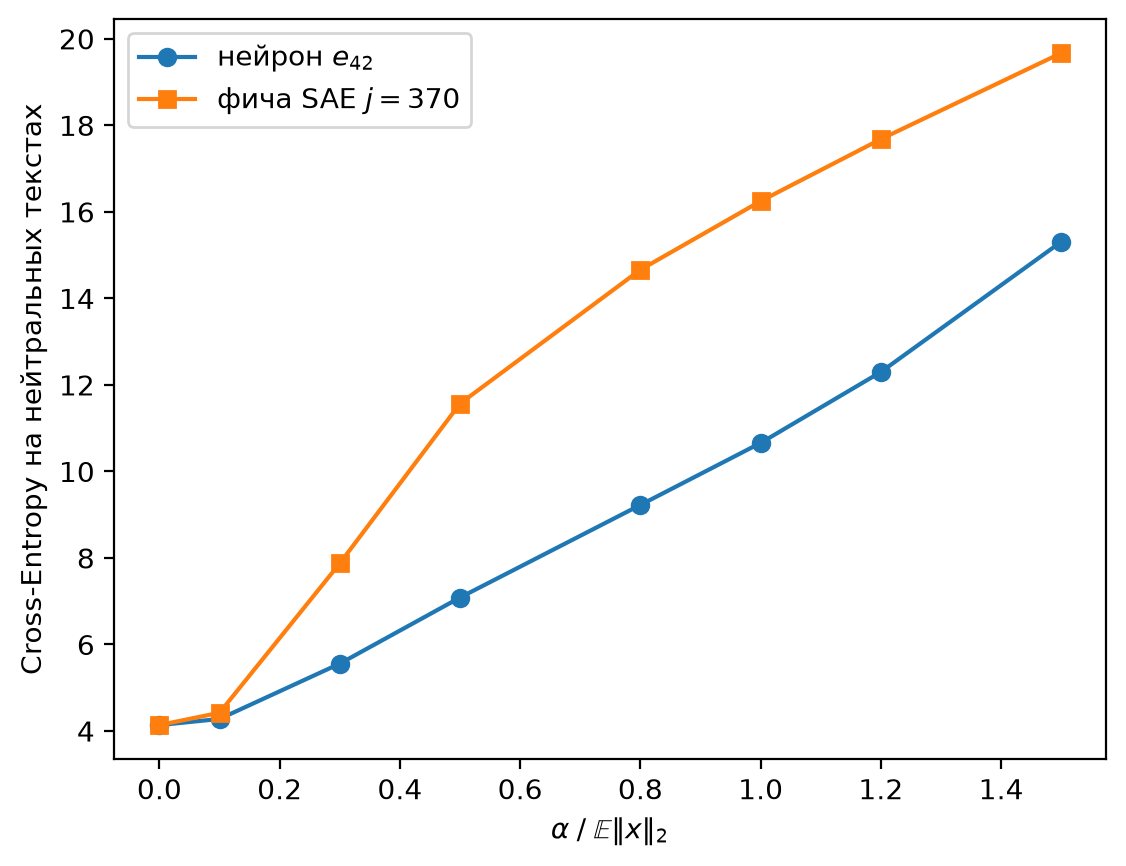

loss нейрон: [4.14, 4.28, 5.56, 7.08, 9.23, 10.66, 12.3, 15.31]
loss фича:   [4.14, 4.42, 7.88, 11.57, 14.66, 16.25, 17.68, 19.67]
Дисперсия активаций вдоль e_42: 0.17, вдоль v_SAE: 1.98


In [ ]:
labels = neutral['input_ids'].masked_fill(neutral['attention_mask'] == 0, -100)

def lm_loss(direction, alpha):
    handle = layer_module.register_forward_hook(make_steering_hook(direction, alpha))
    try:
        with torch.inference_mode():
            loss = model(**neutral, labels=labels, use_cache=False).loss
    finally:
        handle.remove()
    return loss.item()

grid = [0.0] + levels
neuron_loss = [lm_loss(e, k * mean_norm) for k in grid]
feature_loss = [lm_loss(v_sae, k * mean_norm) for k in grid]

_fig, _ax = plt.subplots()
_ax.plot(grid, neuron_loss, marker='o', label='нейрон $e_{42}$')
_ax.plot(grid, feature_loss, marker='s', label=f'фича SAE $j = {j}$')
_ax.set_xlabel(r'$\alpha \;/\; \mathbb{E}\|x\|_2$')
_ax.set_ylabel('Cross-Entropy на нейтральных текстах')
_ax.legend()
plt.show()

print(f'loss нейрон: {[round(l, 2) for l in neuron_loss]}')
print(f'loss фича:   {[round(l, 2) for l in feature_loss]}')
print(f'Дисперсия активаций вдоль e_42: {(X @ e).var():.2f}, вдоль v_SAE: {(X @ v_sae).var():.2f}')

**Что получилось.** При $\alpha = 0$ loss ≈ 4.14. При самом слабом $\alpha$ (0.1 нормы) обе кривые ещё рядом с ним: 4.28 у нейрона и 4.42 у фичи. Дальше кривая фичи везде выше: 7.88 против 5.56 при 0.3 нормы, 19.67 против 15.31 при 1.5 нормы. **В нашем опыте SAE-вектор ломает язык быстрее нейрона**, а не медленнее, как ожидает условие.

**Почему условие ожидает обратного (теория).** Из-за суперпозиции нейрон полисемантичен: ось $e_{42}$ задевает много признаков сразу, толчок по ней включает их вперемешку, и синтаксис рушится. Направление SAE — один признак, которым модель сама пользуется. Толчок по нему меняет одну вещь («открыта скобка»), а остальное, включая грамматику, не трогает.

**Почему у нас вышло наоборот.**
1. *Толчок сильнее всего, что бывает в данных.* В реальных текстах наша фича включается максимум на ≈ 2.5 (таблица топ-5), а самое слабое $\alpha$ сетки — 4.3, следующее — 13. Модель никогда не видела этот признак таким сильным: это уже не «в тексте есть скобка», а сигнал, которого в жизни не бывает.
2. *Модель «слушает» направление фичи и почти не слушает ось 42.* Последняя строка вывода: вдоль $e_{42}$ реальные активации почти не меняются (дисперсия 0.17), вдоль $v_{SAE}$ — в 12 раз сильнее (1.98). SAE учился на реальных активациях, поэтому его направления лежат там, где модель действительно хранит информацию, а следующие слои настроены эту информацию читать. Толчок той же длины по «слушаемому» направлению меняет предсказания сильнее, чем по оси, которой модель почти не пользуется.
3. *Масштаб игрушечный.* Pythia-70m маленькая, SAE обучен 1000 шагов на 64 тыс. токенов, сравниваются одна фича и один нейрон. Обобщать этот результат на большие модели нельзя.

**Как рассказать.** «Ожидание из условия опирается на то, что фича — одно понятие, а нейрон — смесь. По смыслу текста это подтвердилось (контрольное 1), а по loss — нет: при одинаковой норме фича ломает модель сильнее. Причины: сетка $\alpha$ начинается выше естественной силы фичи, а направление фичи модель слушает гораздо внимательнее, чем ось 42».

### Контрольное задание 3. Фазовый переход в бред

**Что делаем.** В сетке из условия переход спрятан между 0.1 нормы (текст нормальный) и 0.3 нормы (мусор). Чтобы найти порог точнее, генерируем текст с фичей SAE на мелкой сетке от 0.10 до 0.30 нормы с шагом 0.02.

In [ ]:
_rows = []
for _k in [0.10, 0.12, 0.14, 0.16, 0.18, 0.20, 0.22, 0.24, 0.26, 0.28, 0.30]:
    _text = generate(v_sae, _k * mean_norm).replace('\n', '⏎')
    _rows.append({'α / E‖x‖': _k, 'α': round(_k * mean_norm, 1), 'продолжение промпта': _text})
mo.md(pd.DataFrame(_rows).to_markdown(index=False))

|   α / E‖x‖ |    α | продолжение промпта                                                                                 |
|-----------:|-----:|:----------------------------------------------------------------------------------------------------|
|       0.1  |  4.3 | a small table in front.⏎⏎"I'm not sure if I can get the right one."⏎⏎"I                             |
|       0.12 |  5.2 | a large table in the front.⏎⏎"The table is a small, but not too large, and the table is             |
|       0.14 |  6.1 | a small, but not too large, and the two sides of the two sides of the two sides of the two sides of |
|       0.16 |  6.9 | a large table in the front.⏎"1.1.1.1.1.1.1.1.                                                       |
|       0.18 |  7.8 | a small, but not too large)the2.1.1.1.1.1.1.1.                                                      |
|       0.2  |  8.7 | a "1"1.2.1.1.1.1.1.1.1.1.1                                                                          |
|       0.22 |  9.5 | a2.2.1.1.1.1.1.1.1.1.1.1.                                                                           |
|       0.24 | 10.4 | a2.2.1.1.1.1.1.1.1.1.1.1.                                                                           |
|       0.26 | 11.3 | a.2.1.1.1.1.1.1.1.1.1.1.1                                                                           |
|       0.28 | 12.1 | one.2.1.1.1.1.1.1.1.1.1.1.1                                                                         |
|       0.3  | 13   | 2.2.1.1.1.1.1.1.1.1.1.1.1                                                                           |

**Что видно.** До 0.14 нормы включительно ($\alpha \le 6.1$) текст связный; повторы вроде «the two sides of the two sides» бывают и у базовой модели. На 0.16–0.18 ($\alpha \approx 7$–8) проступает концепт — закрывающая скобка «)» и нумерация «2.1», как в ссылке «(see 2.1)», — и тут же начинается петля «1.1.1.1». Дальше только «2.2.1.1.1…». **Порог: $\alpha^* \approx 0.15 \cdot \mathbb{E}\|x\|_2 \approx 7$.** Концепт появляется лишь на самой границе: окна, где он уже есть, а текст ещё связный, в нашем опыте практически нет.

**Геометрия.**
1. Реальные активации занимают ограниченную область пространства: вектор обычного токена — это среднее плюс несколько десятков признаков, каждый с силой в пару единиц (наш — не больше ≈ 2.5). Ничего другого модель при обучении не видела.
2. Пока $\alpha$ сравнимо с естественной силой признака, вектор остаётся в этой области, и для модели это просто «в тексте есть скобка».
3. При $\alpha \approx 7$ — это почти 3 максимума фичи и половина длины обычного токена (медиана ≈ 14) — вектор из области выходит. Перед каждым блоком трансформера стоит LayerNorm: он приводит вектор к стандартной длине. Чем длиннее добавка, тем меньше после этого остаётся от исходного смысла токена. А добавка одна и та же во всех позициях, поэтому после нормировки векторы разных токенов становятся похожи друг на друга: модель перестаёт различать контекст, выдаёт самые типичные для скобки токены и дальше копирует уже написанное — получается петля.
4. При $\alpha \approx 13$ (0.3 нормы) добавка уже длиннее вектора обычного токена, и от исходного смысла почти ничего не остаётся.

**Как рассказать.** «Пока толчок сравним с естественной силой признака, модель воспринимает его как обычный признак. Когда он в разы больше всего, что бывает в данных, и сравним с длиной самого вектора токена, активации выходят из области, где живут реальные данные. После LayerNorm от контекста почти ничего не остаётся, и модель зацикливается на самых типичных для признака токенах. У нас это происходит при $\alpha \approx 7$, то есть около 0.15 средней нормы».